# 02-02 · Images as NumPy Arrays
*Section 2: NumPy and Image Basics*

Open an image with PIL, convert it to a NumPy array, and look at its color channels one by one.
See also: [[Image as a NumPy Array]] · [[RGB Color Channels]] · [[Colormaps]]

In [1]:
import numpy as np

In [3]:
import matplotlib.pyplot as plt
%matplotlib inline

In [4]:
from PIL import Image

## 1. Open the image with PIL and convert it
`Image.open()` returns a PIL image object, **not** an array. `np.asarray()` converts it.

In [6]:
pic = Image.open('../DATA/00-puppy.jpg')

In [8]:
type(pic)

PIL.JpegImagePlugin.JpegImageFile

In [9]:
pic_arr = np.asarray(pic)

In [10]:
type(pic_arr)

numpy.ndarray

## 2. Shape = (height, width, channels)
`(1300, 1950, 3)` → 1300 rows (height), 1950 columns (width), 3 color channels (R, G, B). dtype is `uint8` (0–255).

In [11]:
pic_arr.shape

(1300, 1950, 3)

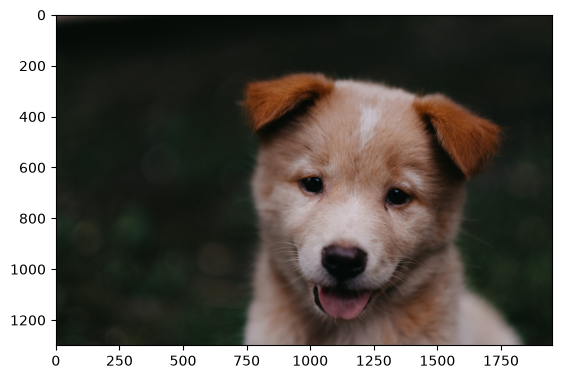

In [12]:
plt.imshow(pic_arr)

## 3. Work on a copy
The array from `np.asarray(pil_image)` is **read-only** (`pic_arr.flags.writeable == False`). Trying `pic_arr[...] = 0` raises `ValueError: assignment destination is read-only`. That's why we take `.copy()` before changing pixels.

In [13]:
pic_red = pic_arr.copy()

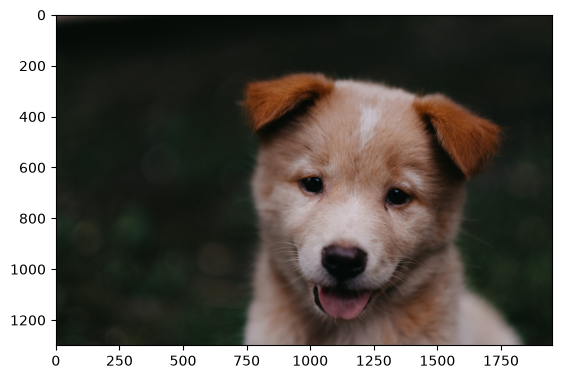

In [14]:
plt.imshow(pic_red)

In [15]:
pic_red.shape

(1300, 1950, 3)

## 4. Look at each channel separately
A single channel is a 2D array, so `imshow` uses a colormap. Without `cmap='gray'` matplotlib uses **viridis** (purple → yellow), which can be misleading for a real image. The puppy's orange ears are bright in the red channel and dark in the blue channel.

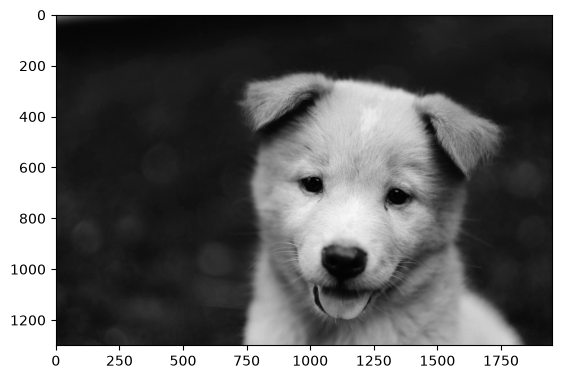

In [ ]:
# Channel order in matplotlib / PIL: R G B  ->  index 0 1 2
# Values go from 0 to 255: 0 = none of that color (black), 255 = full intensity (white)
# Brighter areas = more red in that pixel
plt.imshow(pic_red[:,:,0], cmap='gray')

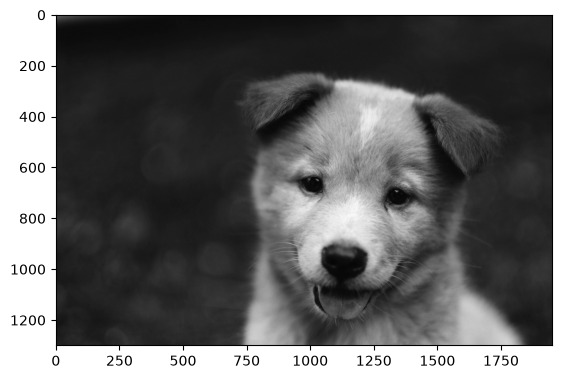

In [19]:
# Green channel
plt.imshow(pic_red[:, :, 1], cmap='gray')

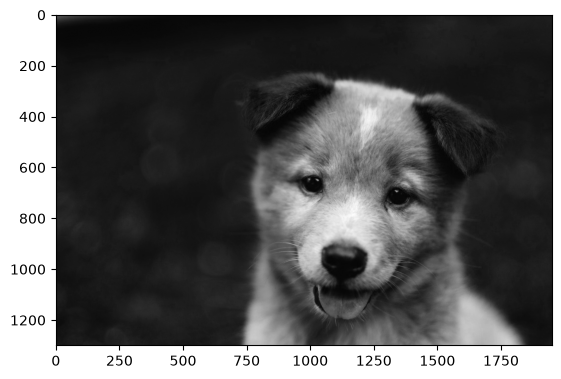

In [20]:
# Blue channel
plt.imshow(pic_red[:, :, 2], cmap='gray')

## 5. Isolate the red channel
Set the other channels to 0 and display the 3-channel array again: only the red information is left.

In [22]:
# zero out the green channel
pic_red[:, :, 1] = 0

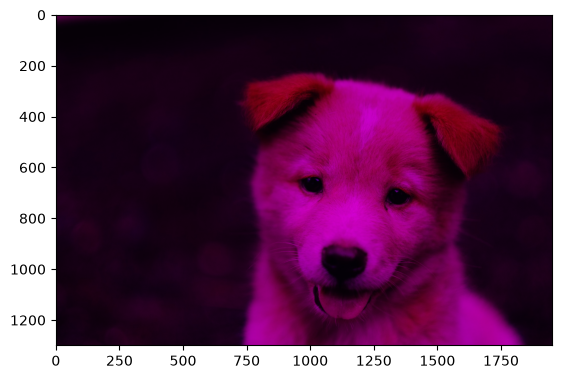

In [24]:
plt.imshow(pic_red)

In [25]:
# zero out the blue channel -> only red is left
pic_red[:,:,2] = 0

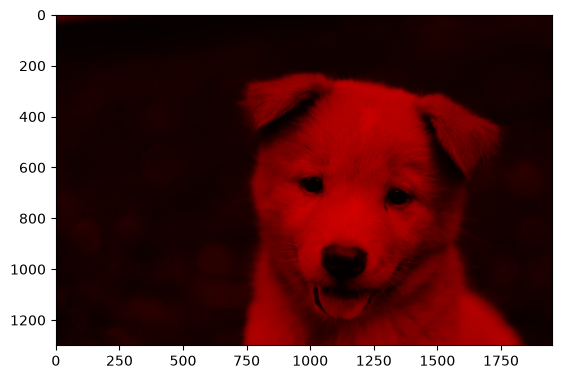

In [26]:
plt.imshow(pic_red)

In [27]:
pic_red.shape

(1300, 1950, 3)

## Summary
- An image is a `(H, W, 3)` `uint8` array; `img[:,:,0]` is red, `[:,:,1]` green, `[:,:,2]` blue.
- Always `.copy()` before editing pixels.
- Use `cmap='gray'` to display a single channel as intensity.